# N143 — budget-matched closed-loop response pilot

Stage: **complete**. Parent accuracy **64.339%**.

Three paired online families; correlated stream; source calibration clips excluded. Exact per-cycle dose:208 updates /31.375 LR units per2,296 received frames. Allocation can force a positive tail despite the point-risk estimate; overrides are logged. No task feedback enters control.

| Family | Arm | Arrivals | Updates | LR sum | Accuracy % | Worst cell % | Risk overrides |
|---|---|---:|---:|---:|---:|---:|---:|
| 5003 | interaction_geometry | 27,552 | 2,496 | 376.500 | 63.217 | 54.497 | 27 |
| 5003 | additive_combined | 27,552 | 2,496 | 376.500 | 63.563 | 55.338 | 29 |
| 5003 | random_quota | 27,552 | 2,496 | 376.500 | 64.180 | 54.699 | 0 |
| 5003 | fixed_quota | 27,552 | 2,496 | 376.500 | 63.972 | 55.467 | 0 |
| 5009 | interaction_geometry | 27,552 | 2,496 | 376.500 | 63.693 | 57.231 | 17 |
| 5009 | additive_combined | 27,552 | 2,496 | 376.500 | 63.744 | 55.371 | 28 |
| 5009 | random_quota | 27,552 | 2,496 | 376.500 | 63.629 | 55.899 | 0 |
| 5009 | fixed_quota | 27,552 | 2,496 | 376.500 | 63.999 | 56.022 | 0 |
| 5011 | interaction_geometry | 27,552 | 2,496 | 376.500 | 63.938 | 55.803 | 20 |
| 5011 | additive_combined | 27,552 | 2,496 | 376.500 | 63.448 | 56.275 | 27 |
| 5011 | random_quota | 27,552 | 2,496 | 376.500 | 63.749 | 56.875 | 0 |
| 5011 | fixed_quota | 27,552 | 2,496 | 376.500 | 64.037 | 55.937 | 0 |

Paired differences use only common completed cycle horizons; no best-checkpoint selection. Readers/checkpoints are not independent training replicates. See comparison.json for per-family trajectory/final contrasts and complete task-cell/CE readouts.

```json
[
  {
    "family": 5003,
    "baseline": "random_quota",
    "cycles": 12,
    "trajectory_mean_delta_pp": -0.843632013516487,
    "latest_common_delta_pp": -0.9623840892695057
  },
  {
    "family": 5003,
    "baseline": "fixed_quota",
    "cycles": 12,
    "trajectory_mean_delta_pp": -0.3589971972558044,
    "latest_common_delta_pp": -0.754972655910187
  },
  {
    "family": 5009,
    "baseline": "random_quota",
    "cycles": 12,
    "trajectory_mean_delta_pp": -0.6736251613824743,
    "latest_common_delta_pp": 0.06367888976758707
  },
  {
    "family": 5009,
    "baseline": "fixed_quota",
    "cycles": 12,
    "trajectory_mean_delta_pp": -0.17238200466064,
    "latest_common_delta_pp": -0.30611338529908494
  },
  {
    "family": 5011,
    "baseline": "random_quota",
    "cycles": 12,
    "trajectory_mean_delta_pp": -0.20558761453964655,
    "latest_common_delta_pp": 0.18961217982300838
  },
  {
    "family": 5011,
    "baseline": "fixed_quota",
    "cycles": 12,
    "trajectory_mean_delta_pp": -0.3863695174892392,
    "latest_common_delta_pp": -0.09830373419407579
  }
]
```


# N143: health response survives; useful allocation does not

Complete: twelve continuations, each receiving 27,552 correlated frames,
2,496 SSL updates and 376.5 nominal LR units, probes included. Independent
verification reconstructed all 1,152 decisions, 144 executed-action audits,
393 raw task readouts, checkpoint fingerprints and matched budgets. Frozen
inputs are unchanged. No new SSL experiment was started during this analysis.

The allocation pilot gives no evidence that either learned selector improves
persistent balanced accuracy. It does show that the SSL learner changes and
that some health-response information remains predictive.

## Accuracy and persistence

Means below use three paired online randomness families, all sharing one
pretrained parent. Each readout refits four C=1 float64 logistic heads from the
fixed 200-label support pools, scoring the same 7,044 queries. The primary
metric averages the twelve post-parent cycle-end accuracies; the endpoint is
secondary. No best-checkpoint selection occurs.

| Allocation | Mean cycle-end accuracy % | Final accuracy % | Final CE |
|---|---:|---:|---:|
| Frozen parent | 64.339 | 64.339 | 0.65800 |
| Random quota | 63.996 | 63.853 | 0.64603 |
| Fixed quota | 63.728 | 64.003 | 0.64650 |
| Additive combined | 63.512 | 63.585 | 0.64907 |
| Interaction geometry | 63.422 | 63.616 | 0.65018 |

Geometry's primary differences versus random are -0.844, -0.674 and -0.206 pp
(mean -0.574 pp). Versus fixed: -0.359, -0.172 and -0.386 pp (mean -0.306 pp).
Combined also trails both controls in every family's trajectory mean. Geometry
finishes slightly above random in two families, but without a sustained advantage.
One unlucky online family does not explain the trajectory result.

Unadjusted 95% t intervals across three families are [-1.395,+0.247] pp versus
random and [-0.595,-0.017] pp versus fixed for geometry's primary difference.
These are descriptive limits: n=3, shared parent, reused development panels,
and multiple comparisons. Readers/checkpoints are not independent replicas.

## The learner changes, while task value diverges from health

Read-only evaluation of every exact final checkpoint preserves complete learner
state. Geometry's bank reconstruction falls 1.09660→0.85693 (21.9% lower),
effective rank rises 3.284→4.285, and feature norm stays near 9.45. Balanced
accuracy nevertheless falls 0.723 pp. Other statistics, including covariance,
also change; this is not uniform improvement of every health dimension.
The result argues against simple stagnation and against using reconstruction
or rank as sufficient task objectives.

There is a cell tradeoff: geometry improves night-highway accuracy 52.78→57.28%,
while night-city accuracy falls 69.55→63.43%. Day-city/day-highway changes are
+1.00/-2.27 pp. All active arms improve the original worst cell while losing
balanced accuracy. With a highway-only training pool, this is consistent with
a shift in domain/class preference, not proof of a particular forgetting mechanism.

CE improves in every arm despite lower argmax accuracy. Parent-fixed-head
accuracy drops to 48–51%, versus 63–64% after refitting: fixed-head compatibility
loss greatly overstates the loss of linearly accessible task information.

## The response model retains more harm information than benefit information

The same 104 non-hold audited actions across all four arms allow paired frozen
forecast comparisons. No refitting or untried-action labeling occurs. Harm is
maximum four-cell accuracy loss; gain is their mean accuracy change.

| Frozen predictor | Harm MSE pp² | Gain MSE pp² |
|---|---:|---:|
| Zero response | 1.85420 | 0.10944 |
| Interaction context | 1.24251 | 0.11959 |
| Additive geometry | 1.06962 | 0.09803 |
| Interaction geometry | 0.91972 | 0.09619 |

Geometry reduces harm error 50.4% versus zero and 26.0% versus context. Gain
error improves only 12.1% versus zero and 1.9% versus additive geometry. Thus
the prior response lead was not entirely spurious, but useful-update forecasting
is much weaker. Harm RMSE is still about 0.96 pp, large relative to the 0.5 pp
risk allowance. Cases share trajectories/readers and are selected executed
actions, not independent counterfactual experiments.

On geometry's OWN 23 positive audited actions, gain MSE is 0.07522 versus 0.07240
for zero. Mean predicted gain is +0.0012 pp; realized gain is -0.0434 pp. Mean
predicted max-cell damage is 0.568 pp versus 1.240 pp realized. Fourteen actions
exceed 0.5 pp actual damage, including six predicted below the threshold.
The point-risk allowance is not calibrated protection. The weaker own-policy
result is consistent with selection/trajectory shift; this audit cannot isolate
its cause. Combined has more own-policy gain information but also underestimates
harm and does not improve retained accuracy.

The response regressions were intentionally frozen. Online gradients train the
SSL learner; task audits do not train the controller's predictor.

## Compulsory spending changes the proposed controller

Across 288 opportunities per arm, every policy executes 72 holds, 36 tiny tails
and 180 quarter tails. Geometry instead requests 43/144/101 without the quota:
tiny falls from 50.0% requested to 12.5% executed, while quarter rises from
35.1% to 62.5%. Combined requests 174/13/101: hold falls from 60.4% to 25.0%.

The quota changes 133 geometry choices (46.2%) and 116 combined choices (40.3%).
It forces choices above the predicted 0.5 pp allowance 64/288 and 84/288 times,
respectively. Zero override counts for random/fixed do not imply zero true risk.

This is a failure of allocation at the specified matched dose. It does not tell
us the outcome of a free guard. Removing the quota also cannot be claimed to
fix retention: those counterfactual outcomes were not observed, and selected
benefit estimates were weak.

Recorded operational time averages 214.5 s for geometry and 220.5 s for combined,
versus 178.3 s random and 179.2 s fixed: about 20–24% extra operating cost without
an accuracy advantage. These times exclude diagnostic evaluation, engineering,
report rendering and discarded work. Low LR dose is not a wall-clock saving.

## Reasonable next step

Do not scale this controller to a near-full drive yet or add predictor complexity
on harm MSE alone. The missing evidence is a label-free signal that ranks
PERSISTENT task benefit on states the controller actually visits.

Use a small forked diagnostic from saved closed-loop checkpoints. Restore the
same full state, measure one paid tiny probe, then cross hold/tiny/quarter tails
on identical frames with paired augmentation seeds. Follow each tail with the
SAME causal sparse continuation, evaluating task differences immediately and
after 256/1,024 arrivals. This continuation must contain actual updates; holding
unchanged weights for longer cannot test persistence. Keep labels offline and
compare geometry against context/zero and combined on the same branches.

If a repeatable benefit signal survives, test an upper-budget controller with
hold ALWAYS available and conservative benefit/risk calibration. Include frozen,
fixed and causal random references. Report actual cost/accuracy tradeoffs rather
than call unequal realized doses matched. This separates signal quality,
compulsory spending and horizon effects.

All populations remain reused development data and branches share a parent.
This short pilot has no full-admission arm. Historical 100s used different probe
support/query protocols; their raw headlines are not direct accuracy baselines.

## Accounting and artifacts

Disk reserve stopped the worker at 112/144 committed branch-cycles. Lossless
compression recovered 118,042,624 bytes with hashes unchanged. Exact resumption
replayed 96 discarded updates and repeated its engineering check. Total actual
SSL work: 30,720 = 29,952 committed + 96 discarded + 672 engineering. Branch
timings omit the discarded attempt; the recovery ledger discloses it separately.

Details: `analysis.json`, `comparison.json`, `independent-verification.json`,
`resume-recovery.json`, `storage-maintenance.json`; analysis code:
`scripts/analyse_budgeted_closed_loop_response.py`.



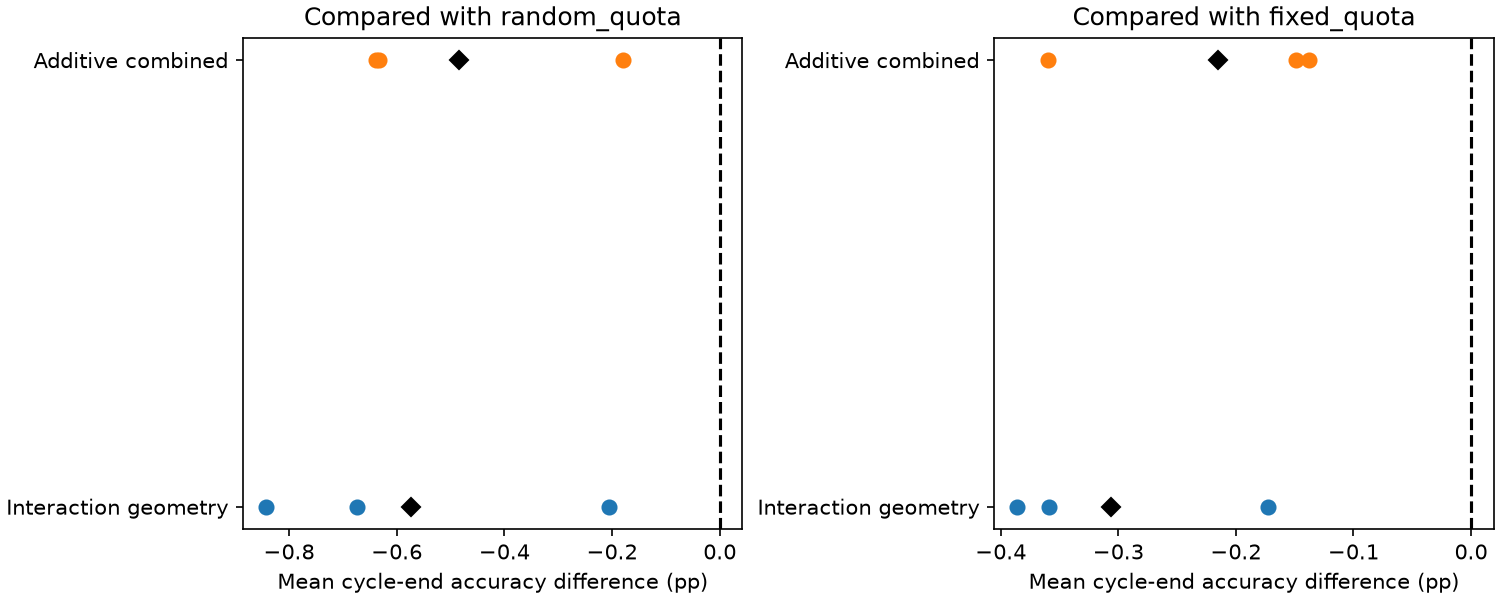

In [ ]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\project\\cafl4ds\\outputs\\closed-loop-response\\20261103-n143\\paired-primary.png'))


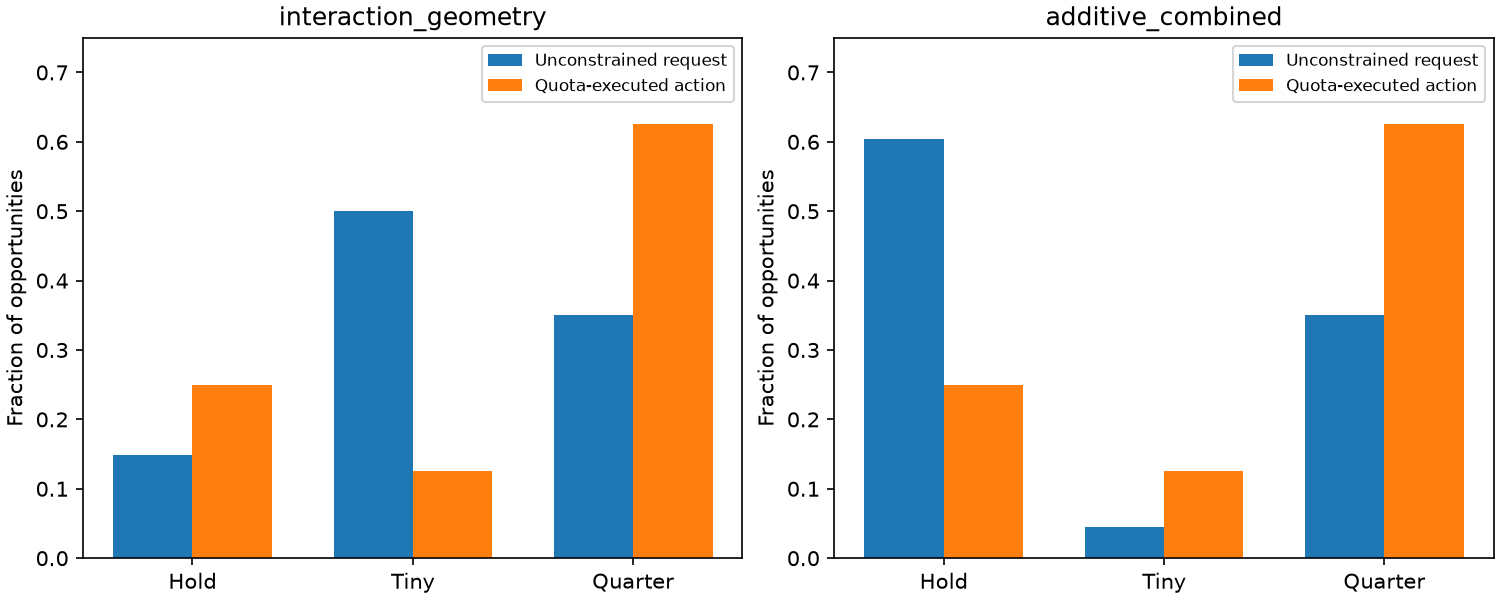

In [ ]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\project\\cafl4ds\\outputs\\closed-loop-response\\20261103-n143\\quota-distortion.png'))


In [1]:
from pathlib import Path
import json
RUN=Path('C:\\CAFL-E\\project\\cafl4ds\\outputs\\closed-loop-response\\20261103-n143')
print(json.dumps(json.loads((RUN/'status.json').read_text()),indent=2))


{
  "stage": "complete",
  "running": false,
  "updated": 1793733958.7535775,
  "scientific_updates": 29952
}


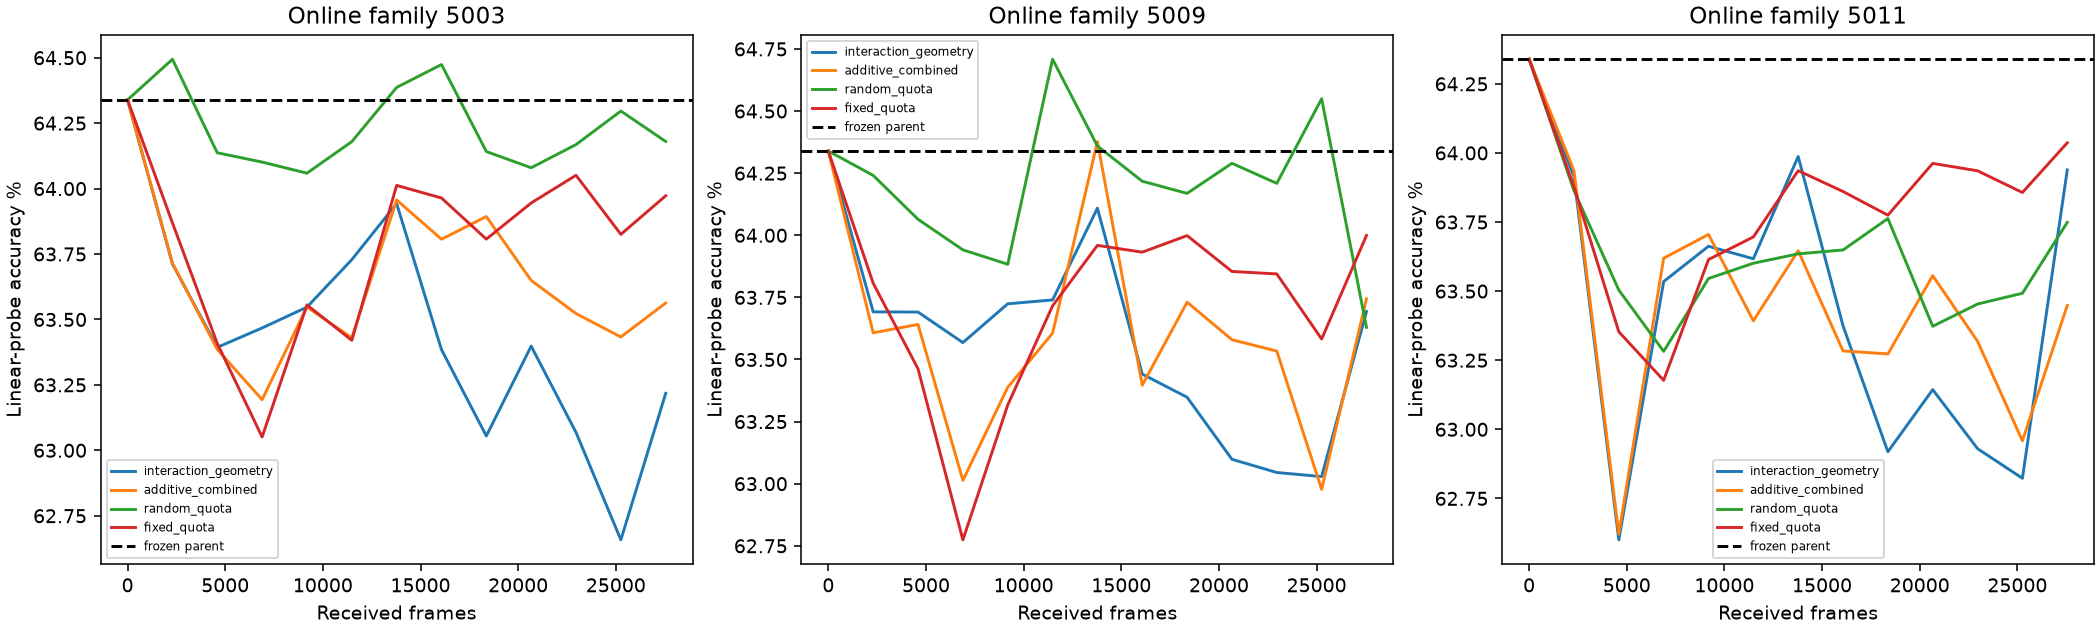

In [2]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\project\\cafl4ds\\outputs\\closed-loop-response\\20261103-n143\\accuracy.png'))


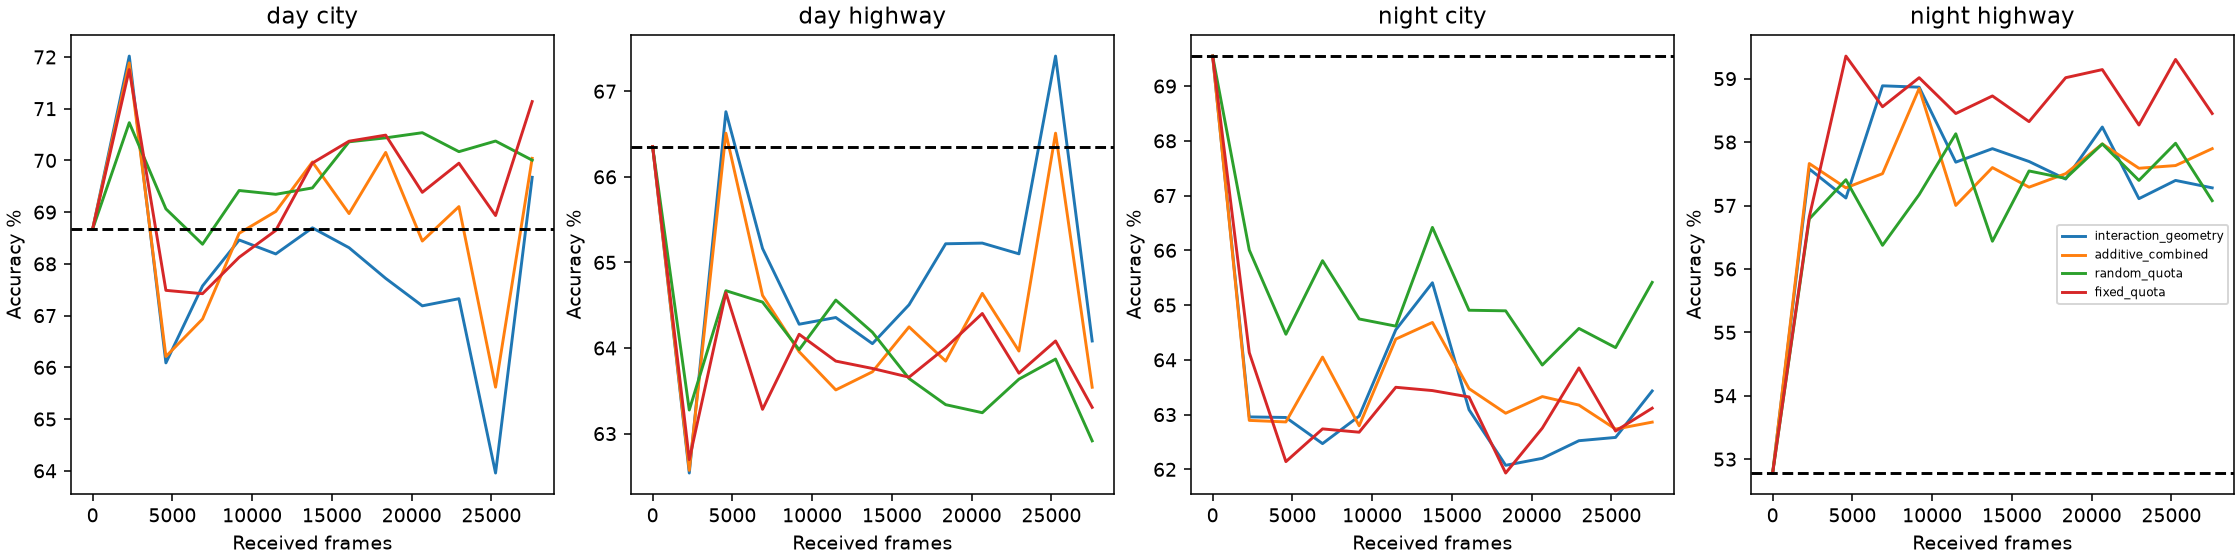

In [3]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\project\\cafl4ds\\outputs\\closed-loop-response\\20261103-n143\\cells.png'))


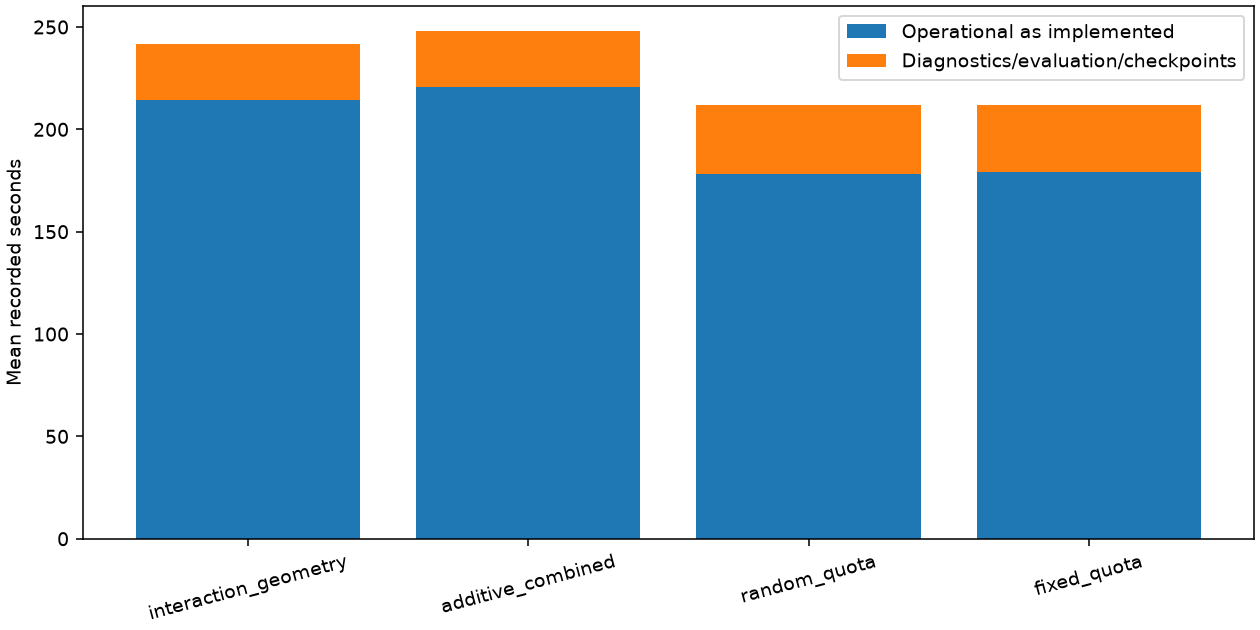

In [4]:
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\project\\cafl4ds\\outputs\\closed-loop-response\\20261103-n143\\cost.png'))
